# 00 · Chuva da bacia (NASA GPM IMERG)

O IMERG Final diário (`GPM_3IMERGDF`, V07) é global: cada arquivo tem ~117 MB e grade 0,1° (3600 × 1800). O fluxo é
**baixar um mês → recortar pela bacia e tirar a média → apagar o bruto → guardar só o CSV**. O código está em `src/imerg.py`.

Este notebook faz um teste de sanidade com os arquivos já baixados e confere o CSV final.

In [ ]:
import sys
sys.path.append("..")
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import config, imerg
plt.rcParams["figure.figsize"] = (11, 3.4); plt.rcParams["axes.grid"] = True

## 1. Teste com os arquivos já baixados em `data/raw/imerg/`
Média sobre a caixa retangular da bacia (sem polígono ainda, então o valor é *diluído*: inclui áreas fora do Taquari-Antas).

In [ ]:
arquivos = sorted(p for p in config.RAW.glob("imerg/*") if p.suffix in (".nc4", ".nc"))
print(len(arquivos), "arquivo(s)")
linhas = []
for f in arquivos:
    dia, media, n = imerg.basin_mean(f)               # sem geom -> caixa BBOX
    linhas.append({"dia": dia.date(), "chuva_media_mm_dia": round(media, 1), "celulas": n, "arquivo": f.name})
pd.DataFrame(linhas)

31 arquivo(s)


,dia,chuva_media_mm_dia,celulas,arquivo
0,2015-01-01,26.9,532,3B-DAY.MS.MRG.3IMERG.20150101-S000000-E235959....
1,2015-01-02,25.4,532,3B-DAY.MS.MRG.3IMERG.20150102-S000000-E235959....
2,2015-01-03,0.1,532,3B-DAY.MS.MRG.3IMERG.20150103-S000000-E235959....
3,2015-01-05,0.2,532,3B-DAY.MS.MRG.3IMERG.20150105-S000000-E235959....
4,2015-01-06,0.2,532,3B-DAY.MS.MRG.3IMERG.20150106-S000000-E235959....
5,2015-01-08,16.0,532,3B-DAY.MS.MRG.3IMERG.20150108-S000000-E235959....
6,2015-01-09,14.1,532,3B-DAY.MS.MRG.3IMERG.20150109-S000000-E235959....
7,2015-01-10,5.7,532,3B-DAY.MS.MRG.3IMERG.20150110-S000000-E235959....
8,2018-07-01,0.0,532,3B-DAY.MS.MRG.3IMERG.20180701-S000000-E235959....
9,2018-07-02,7.3,532,3B-DAY.MS.MRG.3IMERG.20180702-S000000-E235959....


## 2. Baixar o período todo (no **terminal**, não no notebook)

Leva um bom tempo (milhares de arquivos), então rode no terminal do Ubuntu, na raiz do projeto, e deixe aberto. É **retomável**: se interromper (Ctrl+C) ou der erro, rode o mesmo comando e ele continua.

```bash
cd ~/projetos/capstone
conda activate capstone
python -m src.imerg --start 2015-01-01 --end 2026-06-30
```

A cada mês concluído ele imprime `ano-mês: N/N dias em Xs` e guarda a **grade recortada** em `data/processed/imerg_caixa/` (arquivos pequenos).
Os brutos globais são apagados. Para testar antes, use `--start 2023-09-01 --end 2023-09-30`.

**Depois, com o polígono da bacia** (GeoPackage/GeoJSON; ele reprojeta sozinho), recalcule o CSV **sem baixar nada**:

```bash
python -m src.imerg --series-only --basin data/raw/bacia_taquari_antas.gpkg
```

## 3. Conferir as grades guardadas e o CSV

grades: Frozen({'time': 3926, 'lat': 19, 'lon': 28}) | 2015-01-01 -> 2025-09-30


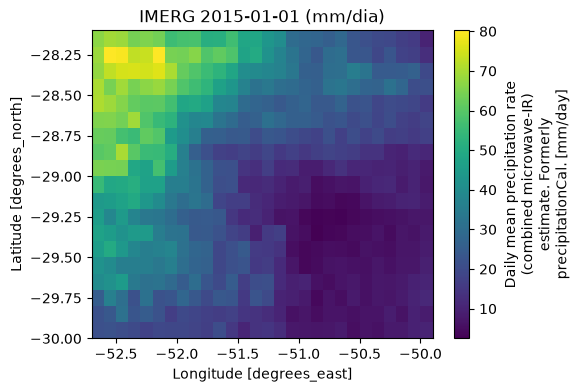

In [ ]:
try:
    da = imerg.load_grids()
except FileNotFoundError as e:
    print(e)
else:
    print("grades:", da.sizes, "|", str(da.time.values[0])[:10], "->", str(da.time.values[-1])[:10])
    dia = da.sel(time=da.time.values[min(len(da.time) - 1, 0)])
    fig, ax = plt.subplots(figsize=(5.5, 4)); dia.plot(ax=ax); ax.set_title(f"IMERG {str(dia.time.values)[:10]} (mm/dia)"); plt.show()

3926 dias | 2015-01-01 -> 2025-09-30 | faltando: 0


count    3926.00
mean        5.02
std        10.96
min         0.00
25%         0.00
50%         0.32
75%         4.65
max       137.90
Name: chuva_bacia_mm, dtype: float64

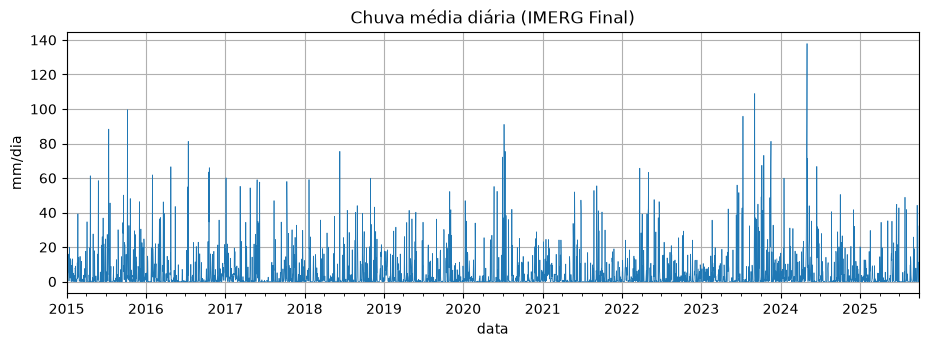

Dias mais chuvosos:


data
2024-05-02    137.9
2023-09-04    108.9
2015-10-08     99.6
2024-05-01     95.9
2023-07-12     95.8
2020-07-07     91.1
2015-07-14     88.3
2023-11-18     81.3
Name: chuva_bacia_mm, dtype: float64

In [ ]:
csv = config.PROCESSED / "chuva_bacia_diaria.csv"
if not csv.exists():
    print("Ainda não existe:", csv)
else:
    chuva = pd.read_csv(csv, parse_dates=["data"], index_col="data")["chuva_bacia_mm"]
    print(len(chuva), "dias |", chuva.index.min().date(), "->", chuva.index.max().date(), "| faltando:", int(chuva.isna().sum()))
    display(chuva.describe().round(2))
    fig, ax = plt.subplots(); chuva.plot(ax=ax, lw=0.5); ax.set_ylabel("mm/dia"); ax.set_title("Chuva média diária (IMERG Final)")
    plt.show()
    print("Dias mais chuvosos:"); display(chuva.nlargest(8).round(1))

## 4. Objetivo desses dados
- Comparar com a chuva das **estações da ANA** (validação do satélite).
- Usar como feature `chuva_bacia` (acumulados de 1–3 dias) no modelo.
- **Registrar na metodologia:** produto, versão, DOI e data de download; dia em UTC (IMERG) × dia local (níveis);
  e a limitação de menor acerto do IMERG em relevo complexo (Serra Gaúcha).